Dimensão do dataset final de features: (6154, 15)
Acurácia Total: 98.62%

Relatório de Classificação:

                                precision    recall  f1-score   support

 1 - Pá quebrada por um quarto       1.00      1.00      1.00        36
                1 - Sem Falhas       0.98      0.93      0.95       109
2 - Pá com um oitavo de quebra       0.95      0.99      0.97       145
       3 - Pá com micro quebra       0.99      1.00      1.00       109
   3 - Pá quebrada pela metade       1.00      1.00      1.00        36
 4 - Pá quebrada por um quarto       0.97      0.97      0.97       109
   5 - Pá quebrada pela metade       1.00      0.98      0.99       108
                5 - Sem falhas       1.00      1.00      1.00        36
          6 - Pá desbalanceada       1.00      1.00      1.00       109
    6 - Pá quebrada totalmente       1.00      1.00      1.00        36
       7 - Pá com micro quebra       1.00      1.00      1.00        36
    7 - Pá quebrada totalmente  

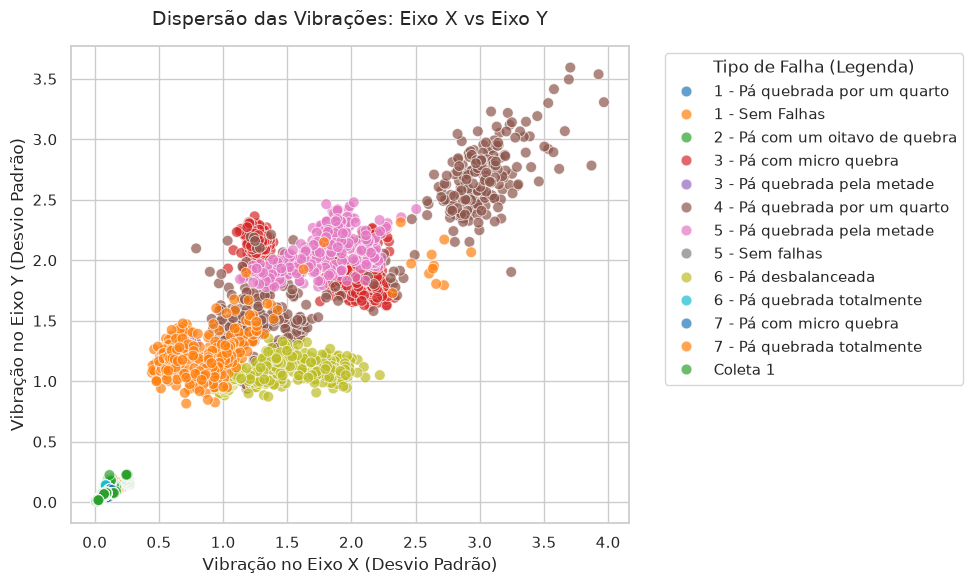

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurações Iniciais
# Facilitará a alteração para os Experimentos 4 e 5 com os outros sensores
CAMINHO_BASE = Path('../datasetventoinha/Experimento3')
TAMANHO_JANELA_MS = 333
RANDOM_SEED = 78

lista_dfs = []

# 2. Iterar por todas as subpastas e ficheiros dinamicamente

classes_validas = [
    '1 - Pá quebrada por um quarto',
    '2 - Pá com um oitavo de quebra',
    '3 - Pá quebrada pela metade',
    '4 - Pá desbalanceada',
    '5 - Sem falhas',
    '6 - Pá quebrada totalmente',
    '7 - Pá com micro quebra'
]

for id_coleta, ficheiro in enumerate(CAMINHO_BASE.rglob('*.xlsx')):
    try:
        df_temp = pd.read_excel(ficheiro)
        
        nome_pasta = ficheiro.parent.name
        nome_arquivo = ficheiro.stem # Nome do ficheiro sem a extensão .xlsx
        
        # Se o nome da pasta for uma das classes conhecidas, usamos a pasta
        if nome_pasta in classes_validas:
            nome_classe = nome_pasta
        else:
            nome_classe = nome_arquivo
            
        df_temp['classificacao'] = nome_classe
        df_temp['id_coleta'] = id_coleta 
        
        lista_dfs.append(df_temp)

    
        
    except Exception as e:
        print(f"Erro ao ler o ficheiro {ficheiro.name}: {e}")
        
if not lista_dfs:
    raise ValueError("Nenhum ficheiro Excel foi encontrado ou lido com sucesso. Reveja")

# 3. Junta todos os DataFrames carregados num só
df_unificado = pd.concat(lista_dfs, ignore_index=True)

# 4. Garante que Tempo_ms seja numérico e cria a janela de tempo
df_unificado['Tempo_ms'] = pd.to_numeric(df_unificado['Tempo_ms'], errors='coerce')
df_unificado = df_unificado.dropna(subset=['Tempo_ms'])

# Cria a coluna ID_Janela
df_unificado['ID_Janela'] = (df_unificado['Tempo_ms'] // TAMANHO_JANELA_MS).astype(int)

# 5. Extração das Features (Agrupamento por classificação, id_coleta e ID_Janela)
df_features = (
    df_unificado.groupby(['classificacao', 'id_coleta', 'ID_Janela'])
    .agg(
        Ax_Mean=('Ax_g', 'mean'),
        Ax_Std=('Ax_g', 'std'),
        Ax_Max=('Ax_g', 'max'),
        Ax_Min=('Ax_g', 'min'),
        Ay_Mean=('Ay_g', 'mean'),
        Ay_Std=('Ay_g', 'std'),
        Ay_Max=('Ay_g', 'max'),
        Ay_Min=('Ay_g', 'min'),
        Az_Mean=('Az_g', 'mean'),
        Az_Std=('Az_g', 'std'),
        Az_Max=('Az_g', 'max'),
        Az_Min=('Az_g', 'min'),
    )
    .reset_index()
)

# Removemos linhas com NaN (ex: janelas com apenas 1 amostra onde o desvio padrão é NaN)
df_features = df_features.dropna().reset_index(drop=True)
print("Dimensão do dataset final de features:", df_features.shape)

# 6. Preparação das variáveis X e y
# Removemos as colunas de identificação para não enviesar o modelo
X = df_features.drop(columns=['classificacao', 'id_coleta', 'ID_Janela'])
y = df_features['classificacao']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

# 7. Treino e avaliação com RandomForest
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Acurácia Total: {acc * 100:.2f}%\n")
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred))


#Parte Gráfica.


# 1. Configura o estilo e o tamanho da imagem
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 2. Cria o Gráfico de Dispersão (Scatter Plot)
# x e y: Escolhemos o Desvio Padrão de X e Y como exemplo
# hue: Colore os pontos automaticamente baseando-se na coluna 'classificacao'
sns.scatterplot(
    data=df_features, 
    x='Ax_Std', 
    y='Ay_Std', 
    hue='classificacao', 
    palette='tab10',  # Paleta com cores bem distintas
    alpha=0.7,        # Deixa os pontos levemente transparentes (ajuda a ver sobreposições)
    s=60              # Tamanho dos pontos
)

# 3. Adiciona títulos e rótulos aos eixos
plt.title('Dispersão das Vibrações: Eixo X vs Eixo Y', fontsize=14, pad=15)
plt.xlabel('Vibração no Eixo X (Desvio Padrão)', fontsize=12)
plt.ylabel('Vibração no Eixo Y (Desvio Padrão)', fontsize=12)

# 4. Ajusta a legenda para ficar fora do gráfico e não cobrir os pontos
plt.legend(title='Tipo de Falha (Legenda)', bbox_to_anchor=(1.05, 1), loc='upper left')

# 5. Ajusta o layout para nada ficar cortado e exibe o gráfico
plt.tight_layout()
plt.show()